# 06 · Model training

**Data science step 6 of 7:** train ML models, watch them learn, and pick the best one.

**Input:** `examples_dev.parquet` (from notebook 04)
**Train on:** Sept 1–20 · **Compare on:** valid, Sept 21–25 · **Bar to beat:** historical baseline, **MAE ≈ 18.0**

| # | Model | What it is |
|---|---|---|
| 1 | Linear regression | One weight per feature: prediction = w₁·x₁ + w₂·x₂ + … |
| 2 | Decision tree | A flowchart of yes/no questions |
| 3 | Gradient boosting | Hundreds of small trees, each fixing the previous ones' mistakes |
| 4 | **Residual boosting** | Boosting that learns the *correction* to the historical baseline |
| 5 | Neural network | Layers of neurons trained epoch by epoch |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

DATA = Path("data/processed")
FIGURES = Path("reports/figures")

NUMERIC_FEATURES = [
    "cur_delay", "prev_delay", "delay_change", "origin_delay", "max_delay_so_far",
    "stop_no", "stops_left", "km_done", "km_left", "share_done",
    "sched_min_left", "planned_kmh_left", "total_km", "n_stops", "hour", "dow", "is_special",
    "hist_change", "hist_train_dest", "hist_station_gain", "hist_n_trips",
]
CATEGORICAL_FEATURES = ["zone", "train_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

dev = pd.read_parquet(DATA / "examples_dev.parquet")
train = dev[dev["split"] == "train"]
valid = dev[dev["split"] == "valid"]

X_train, y_train = train[FEATURES], train["target"].to_numpy()
X_valid, y_valid = valid[FEATURES], valid["target"].to_numpy()
print(f"X_train {X_train.shape} | X_valid {X_valid.shape}")

X_train (729385, 23) | X_valid (182384, 23)


In [2]:
def evaluate(y_true, y_pred):
    error = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        "MAE": np.mean(np.abs(error)),
        "MedianAE": np.median(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "R2": 1 - np.sum(error ** 2) / np.sum((y_true - np.mean(y_true)) ** 2),
        "within_10min_%": 100 * np.mean(np.abs(error) <= 10),
        "within_30min_%": 100 * np.mean(np.abs(error) <= 30),
        "bias": np.mean(error),
    }


def historical_baseline(X):
    # Current delay + this train's usual change from this station to the destination
    return np.clip(X["cur_delay"] + X["hist_change"].fillna(0), 0, None).to_numpy()


results = {}            # valid scores of every model, compared at the end
results["Historical baseline"] = evaluate(y_valid, historical_baseline(X_valid))
results["Historical baseline"]

{'MAE': np.float64(18.02307219931573),
 'MedianAE': np.float64(4.0),
 'RMSE': np.float64(48.16042779638888),
 'R2': np.float64(0.7106568058003935),
 'within_10min_%': np.float64(66.15273269585052),
 'within_30min_%': np.float64(85.20977717343627),
 'bias': np.float64(-0.4222135713659093)}

---
## Model 1: Linear regression

Linear regression needs **numbers only, no missing values**. Preprocessing:
- **numeric:** fill missing with the median (`SimpleImputer`), then put all features on the same scale (`StandardScaler`: mean 0, std 1)
- **categorical:** one column per value (`OneHotEncoder`): `zone = "KRCL"` → `zone_KRCL = 1`, all other zone columns = 0

A **pipeline** chains preprocessing + model, so exactly the same steps are applied to train and valid.

In [3]:
linear = make_pipeline(
    ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ]),
    LinearRegression(),
)

start = time.time()
linear.fit(X_train, y_train)
pred = np.clip(linear.predict(X_valid), 0, None)     # a delay can't be negative
print(f"trained in {time.time() - start:.1f}s")

results["Linear regression"] = evaluate(y_valid, pred)
results["Linear regression"]

trained in 3.1s


{'MAE': np.float64(20.829670721894658),
 'MedianAE': np.float64(8.255374741035508),
 'RMSE': np.float64(47.003941792870286),
 'R2': np.float64(0.7243860729441638),
 'within_10min_%': np.float64(54.367707693657344),
 'within_30min_%': np.float64(81.37062461619439),
 'bias': np.float64(3.0356516448955255)}

**What did it learn?** Because features were scaled, the weights can be compared: a bigger weight = a bigger effect of a 1-standard-deviation change.

In [4]:
names = linear[0].get_feature_names_out()
weights = pd.Series(linear[-1].coef_, index=names)
weights.reindex(weights.abs().sort_values(ascending=False).index).head(10).round(1)

num__cur_delay              83.2
num__hist_change            25.0
num__km_left                13.0
cat__zone_SECR              10.7
cat__train_type_special     10.1
num__sched_min_left         -9.5
num__prev_delay             -8.2
cat__train_type_rajdhani    -8.2
num__origin_delay            7.4
num__total_km                6.6
dtype: float64

`cur_delay` dominates, as expected. But a linear model can only add up straight-line effects. It can't express things like *"a big delay shrinks near the end, but only on padded routes"*. MAE ≈ 20.8: **worse than the historical baseline.**

---
## Model 2: Decision tree

A tree asks yes/no questions (*"is `cur_delay` ≤ 150?"*) and predicts the average target of the rows that end up in each final box (**leaf**). It handles interactions naturally.
- `max_depth=12`: at most 12 questions in a row
- `min_samples_leaf=200`: each leaf needs at least 200 examples, so it can't memorise single journeys (**overfitting**)

In [5]:
tree = make_pipeline(
    ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
    ]),
    DecisionTreeRegressor(max_depth=12, min_samples_leaf=200, random_state=42),
)

start = time.time()
tree.fit(X_train, y_train)
pred = tree.predict(X_valid)
print(f"trained in {time.time() - start:.1f}s | {tree[-1].get_n_leaves():,} leaves, depth {tree[-1].get_depth()}")

results["Decision tree"] = evaluate(y_valid, pred)
results["Decision tree"]

trained in 7.4s | 512 leaves, depth 12


{'MAE': np.float64(19.803356382356817),
 'MedianAE': np.float64(4.778477798882892),
 'RMSE': np.float64(49.92140479187772),
 'R2': np.float64(0.6891103990626182),
 'within_10min_%': np.float64(68.3168479691201),
 'within_30min_%': np.float64(84.53921396613738),
 'bias': np.float64(0.7324519439064968)}

The first two levels of the tree. Each box shows the question, the number of examples, and their average destination delay (`value`):

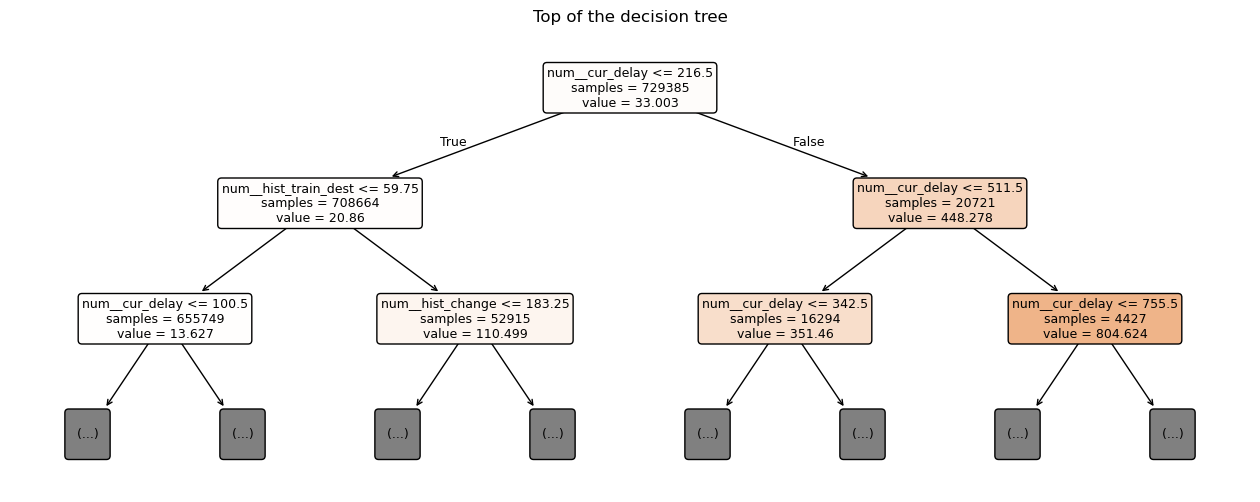

In [6]:
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(tree[-1], max_depth=2, feature_names=list(tree[0].get_feature_names_out()),
          filled=True, rounded=True, fontsize=9, impurity=False, ax=ax)
ax.set_title("Top of the decision tree")
plt.show()

---
## Model 3: Gradient boosting

**Idea:** train tree 1. Look at its mistakes. Train tree 2 **on those mistakes**. Then tree 3 on the remaining mistakes, and so on. Each **round** adds one small tree.

> 💡 **Rounds vs epochs.** Neural networks train in **epochs** (one full pass over the data). Boosting trains in **rounds** (one new tree each). Both are steps of learning, and in both you watch the **validation error** to know when to stop.

We use scikit-learn's `HistGradientBoostingRegressor`, the same algorithm family as LightGBM and XGBoost. It handles missing values and categories by itself.

The **loss function** is what the model tries to minimise:
- `absolute_error`: matches our MAE metric
- `poisson`: designed for non-negative, skewed counts like delays

The helper below prints the error **round by round** while the model learns:

In [7]:
train_sample = train.sample(100_000, random_state=42)       # a sample is enough to track training error
X_train_sample, y_train_sample = train_sample[FEATURES], train_sample["target"].to_numpy()


def training_log(model, base_train=0, base_valid=0, every=25):
    # Train and valid MAE after every boosting round. Prints one line every `every` rounds.
    rows = []
    stages = zip(model.staged_predict(X_train_sample), model.staged_predict(X_valid))
    for round_no, (p_train, p_valid) in enumerate(stages, start=1):
        train_mae = np.mean(np.abs(np.clip(base_train + p_train, 0, None) - y_train_sample))
        valid_mae = np.mean(np.abs(np.clip(base_valid + p_valid, 0, None) - y_valid))
        rows.append({"round": round_no, "train_MAE": train_mae, "valid_MAE": valid_mae})
        if round_no == 1 or round_no % every == 0:
            print(f"round {round_no:>3}/{model.max_iter} | train MAE {train_mae:6.2f} | valid MAE {valid_mae:6.2f}")
    return pd.DataFrame(rows).set_index("round")

### 3a. Boosting with absolute loss

In [8]:
gb_absolute = HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, max_leaf_nodes=63,
                                            categorical_features="from_dtype", early_stopping=False, random_state=42)
start = time.time()
gb_absolute.fit(X_train, y_train)
print(f"trained in {time.time() - start:.1f}s\n")

log_absolute = training_log(gb_absolute)
results["Boosting, absolute loss"] = evaluate(y_valid, np.clip(gb_absolute.predict(X_valid), 0, None))

trained in 7.1s

round   1/200 | train MAE  33.29 | valid MAE  28.78


round  25/200 | train MAE  33.29 | valid MAE  28.78
round  50/200 | train MAE  33.29 | valid MAE  28.78
round  75/200 | train MAE  33.29 | valid MAE  28.78


round 100/200 | train MAE  33.29 | valid MAE  28.78
round 125/200 | train MAE  33.29 | valid MAE  28.78


round 150/200 | train MAE  33.29 | valid MAE  28.78


round 175/200 | train MAE  33.29 | valid MAE  28.78


round 200/200 | train MAE  33.29 | valid MAE  28.78


⚠️ **The error never moves.** The model is stuck predicting 0 for everyone.

**Why?** With absolute loss, the best single guess is the **median**, and 66% of targets are exactly 0, so the model starts at 0. Every new tree is fitted to the *direction* of the errors, and in most groups the majority of rows are already exactly right at 0, so every tree adds 0. The model never moves.

**Lesson:** the loss function and the shape of the target have to fit each other.

### 3b. Boosting with Poisson loss

In [9]:
gb_poisson = HistGradientBoostingRegressor(loss="poisson", max_iter=400, max_leaf_nodes=63,
                                           categorical_features="from_dtype", early_stopping=False, random_state=42)
start = time.time()
gb_poisson.fit(X_train, y_train)
print(f"trained in {time.time() - start:.1f}s\n")

log_poisson = training_log(gb_poisson, every=50)
results["Boosting, poisson loss"] = evaluate(y_valid, gb_poisson.predict(X_valid))

trained in 24.2s

round   1/400 | train MAE  45.38 | valid MAE  42.69


round  50/400 | train MAE  18.80 | valid MAE  19.51


round 100/400 | train MAE  17.18 | valid MAE  19.18
round 150/400 | train MAE  16.19 | valid MAE  19.05


round 200/400 | train MAE  15.33 | valid MAE  18.91
round 250/400 | train MAE  14.58 | valid MAE  18.80


round 300/400 | train MAE  14.00 | valid MAE  18.75
round 350/400 | train MAE  13.46 | valid MAE  18.72


round 400/400 | train MAE  12.95 | valid MAE  18.65


This one learns: the error falls round after round. But it ends around **18.7**, still not better than the historical baseline (18.0).

---
## Model 4: Residual boosting, learning the correction

The historical baseline already knows a lot. So instead of predicting the delay from scratch, the model learns **how much the baseline is wrong**:

```
model target  = actual destination delay − historical baseline
prediction    = historical baseline + model(features)
```

The new target is centred around 0 and spread on both sides, so absolute loss works again. This is a common industry technique: **start from a strong simple rule, and let ML learn its mistakes.**

We train for **400 rounds** and watch both errors:

In [10]:
base_train = historical_baseline(X_train)
base_train_sample = historical_baseline(X_train_sample)
base_valid = historical_baseline(X_valid)

gb_residual = HistGradientBoostingRegressor(loss="absolute_error", max_iter=400, max_leaf_nodes=127,
                                            min_samples_leaf=100, l2_regularization=1.0, learning_rate=0.1,
                                            categorical_features="from_dtype", early_stopping=False, random_state=42)
start = time.time()
gb_residual.fit(X_train, y_train - base_train)            # target = the correction
print(f"trained in {time.time() - start:.1f}s\n")

log_residual = training_log(gb_residual, base_train_sample, base_valid, every=20)

trained in 46.2s

round   1/400 | train MAE  20.07 | valid MAE  17.75


round  20/400 | train MAE  17.62 | valid MAE  15.63
round  40/400 | train MAE  16.94 | valid MAE  15.11
round  60/400 | train MAE  16.49 | valid MAE  14.84


round  80/400 | train MAE  16.28 | valid MAE  14.77
round 100/400 | train MAE  16.15 | valid MAE  14.75
round 120/400 | train MAE  16.00 | valid MAE  14.75


round 140/400 | train MAE  15.75 | valid MAE  14.74
round 160/400 | train MAE  15.47 | valid MAE  14.75
round 180/400 | train MAE  15.34 | valid MAE  14.74


round 200/400 | train MAE  15.27 | valid MAE  14.73
round 220/400 | train MAE  15.11 | valid MAE  14.74
round 240/400 | train MAE  14.97 | valid MAE  14.76


round 260/400 | train MAE  14.69 | valid MAE  14.78
round 280/400 | train MAE  14.58 | valid MAE  14.78
round 300/400 | train MAE  14.52 | valid MAE  14.78


round 320/400 | train MAE  14.38 | valid MAE  14.82
round 340/400 | train MAE  14.24 | valid MAE  14.85
round 360/400 | train MAE  14.17 | valid MAE  14.87


round 380/400 | train MAE  14.02 | valid MAE  14.87
round 400/400 | train MAE  13.96 | valid MAE  14.89


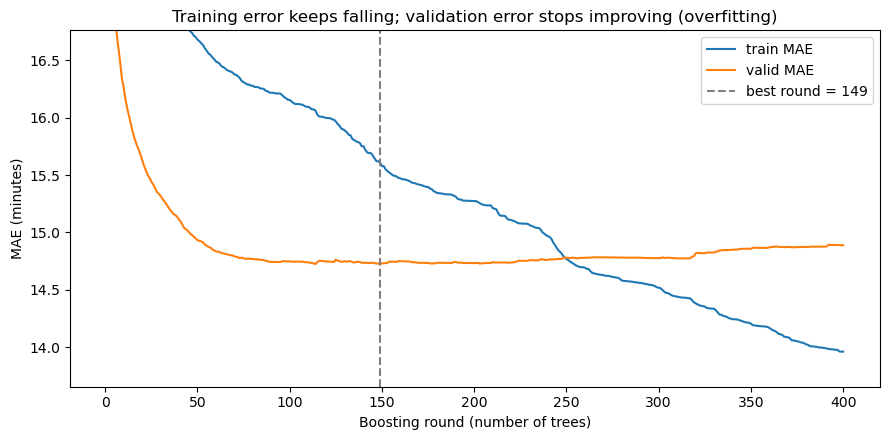

best valid MAE 14.72 at round 149 | at round 400: train 13.96, valid 14.89


In [11]:
best_round = int(log_residual["valid_MAE"].idxmin())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(log_residual.index, log_residual["train_MAE"], label="train MAE")
ax.plot(log_residual.index, log_residual["valid_MAE"], label="valid MAE")
ax.axvline(best_round, color="grey", ls="--", label=f"best round = {best_round}")
ax.set_title("Training error keeps falling; validation error stops improving (overfitting)")
ax.set_xlabel("Boosting round (number of trees)")
ax.set_ylabel("MAE (minutes)")
ax.set_ylim(top=log_residual["valid_MAE"].iloc[5])
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "training_curve_boosting.png", dpi=120)
plt.show()

print(f"best valid MAE {log_residual['valid_MAE'].min():.2f} at round {best_round} | "
      f"at round 400: train {log_residual['train_MAE'].iloc[-1]:.2f}, valid {log_residual['valid_MAE'].iloc[-1]:.2f}")

### Reading the training curve
- **Train MAE keeps going down:** the model keeps fitting the training data better
- **Valid MAE goes down, then flattens and slowly rises:** after that, the extra trees learn noise from the training dates that doesn't carry over to new dates. That's **overfitting**.
- We stop at the **best validation round** (≈150). That's the setting used for the final model in notebook 07.

**Why is train MAE *higher* than valid MAE for most of the curve?** It looks backwards, but it's expected here. Training rows get **out-of-fold** history features (notebook 04): each one is built from only 16 of the 20 training days, so `hist_change` is less accurate for them than for valid rows, whose history uses all 20 days. Different dates also simply have different delays. Compare the **shapes**, not the levels: train keeps falling, valid flattens.

In [12]:
pred = np.clip(base_valid + np.array(list(gb_residual.staged_predict(X_valid))[best_round - 1]), 0, None)
results["Residual boosting (final)"] = evaluate(y_valid, pred)
results["Residual boosting (final)"]

{'MAE': np.float64(14.722438924795858),
 'MedianAE': np.float64(0.11741402015105395),
 'RMSE': np.float64(46.19584452331974),
 'R2': np.float64(0.7337813838361793),
 'within_10min_%': np.float64(76.38005526800596),
 'within_30min_%': np.float64(87.74673216948855),
 'bias': np.float64(-7.424721907960068)}

---
## Model 5: Neural network, trained in epochs

A **multi-layer perceptron** (MLP): inputs → 64 neurons → 32 neurons → 1 output.
- One **epoch** = the network sees all 729k training examples once, in mini-batches of 2,048
- After each batch, every weight is nudged to reduce the error (**gradient descent**, here the *Adam* optimiser)
- Like linear regression, it needs scaled numbers with no missing values

To give it a fair chance, it also learns the **correction to the historical baseline**. Its loss is **squared error**, so the correction is clipped to ±300 min to stop a few 30-hour delays from dominating training.

In [13]:
nn_preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])
Z_train = nn_preprocess.fit_transform(X_train)        # learn scaling from TRAIN only
Z_valid = nn_preprocess.transform(X_valid)
nn_target = np.clip(y_train - base_train, -300, 300)
print("network input shape:", Z_train.shape)

network = MLPRegressor(hidden_layer_sizes=(64, 32), batch_size=2048, learning_rate_init=0.001, random_state=42)

EPOCHS = 20
history = []
start = time.time()
for epoch in range(1, EPOCHS + 1):
    network.partial_fit(Z_train, nn_target)           # one full pass over the training data
    valid_mae = np.mean(np.abs(np.clip(base_valid + network.predict(Z_valid), 0, None) - y_valid))
    history.append({"epoch": epoch, "train_loss": network.loss_, "valid_MAE": valid_mae})
    print(f"epoch {epoch:>2}/{EPOCHS} | train loss {network.loss_:7.1f} | valid MAE {valid_mae:.2f} | {time.time() - start:4.0f}s")

history = pd.DataFrame(history).set_index("epoch")

network input shape: (729385, 49)


epoch  1/20 | train loss   995.6 | valid MAE 19.18 |    2s


epoch  2/20 | train loss   934.9 | valid MAE 19.11 |    4s


epoch  3/20 | train loss   915.0 | valid MAE 18.99 |    7s


epoch  4/20 | train loss   902.4 | valid MAE 18.91 |    9s


...

epoch 16/20 | train loss   817.4 | valid MAE 18.49 |   32s


epoch 17/20 | train loss   812.4 | valid MAE 18.46 |   34s


epoch 18/20 | train loss   807.6 | valid MAE 18.44 |   36s


epoch 19/20 | train loss   803.0 | valid MAE 18.43 |   38s


epoch 20/20 | train loss   798.7 | valid MAE 18.42 |   39s


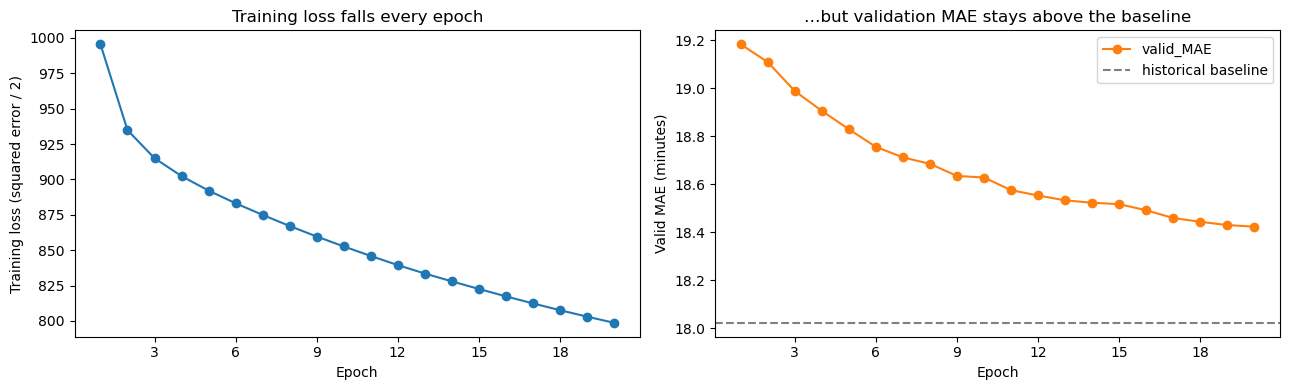

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history["train_loss"].plot(marker="o", ax=axes[0])
axes[0].set_title("Training loss falls every epoch")
axes[0].set_ylabel("Training loss (squared error / 2)")
history["valid_MAE"].plot(marker="o", color="tab:orange", ax=axes[1])
axes[1].axhline(results["Historical baseline"]["MAE"], color="grey", ls="--", label="historical baseline")
axes[1].set_title("…but validation MAE stays above the baseline")
axes[1].set_ylabel("Valid MAE (minutes)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(FIGURES / "training_curve_neural_network.png", dpi=120)
plt.show()

results["Neural network"] = evaluate(y_valid, np.clip(base_valid + network.predict(Z_valid), 0, None))

The network **is learning** (the loss falls every epoch), but it ends **behind the historical baseline** and far behind boosting. Two reasons:
1. **On tabular data** (rows and columns of mixed features), tree-based boosting usually beats neural networks. Neural networks shine on images, text and audio.
2. Its loss is **squared error**, which aims at the *average*, while we're scored on **MAE**, which rewards aiming at the *median*. With a skewed target those are very different.

---
## Comparison of all models (valid set)

In [15]:
comparison = pd.DataFrame(results).T.sort_values("MAE").round(2)
comparison

,MAE,MedianAE,RMSE,R2,within_10min_%,within_30min_%,bias
Residual boosting (final),14.72,0.12,46.20,0.73,76.38,87.75,-7.42
Historical baseline,18.02,4.00,48.16,0.71,66.15,85.21,-0.42
Neural network,18.42,5.64,45.84,0.74,64.89,85.18,0.33
"Boosting, poisson loss",18.65,4.39,51.58,0.67,69.59,85.82,-1.54
Decision tree,19.80,4.78,49.92,0.69,68.32,84.54,0.73
Linear regression,20.83,8.26,47.00,0.72,54.37,81.37,3.04
"Boosting, absolute loss",28.78,0.00,94.05,-0.10,75.83,83.90,-28.78


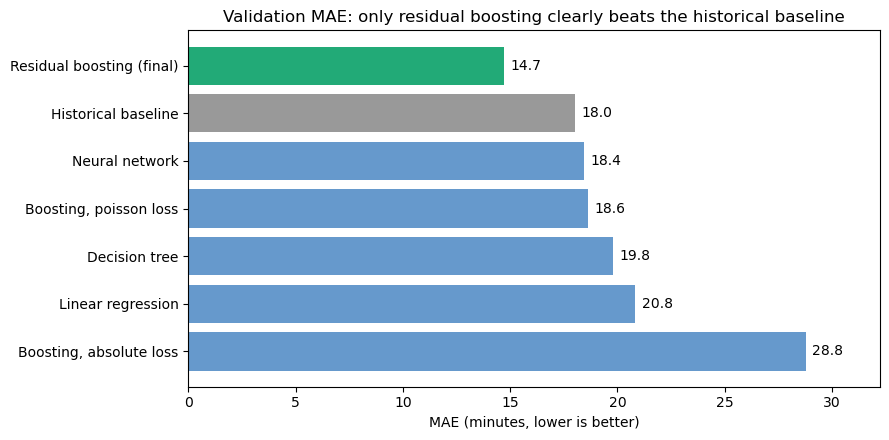

In [16]:
order = comparison["MAE"].sort_values(ascending=False)
colors = ["#2a7" if name == "Residual boosting (final)" else "#999" if "baseline" in name else "#69c"
          for name in order.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order.index, order.values, color=colors)
for i, v in enumerate(order.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set_xlim(0, order.max() * 1.12)
ax.set_title("Validation MAE: only residual boosting clearly beats the historical baseline")
ax.set_xlabel("MAE (minutes, lower is better)")
plt.tight_layout()
plt.savefig(FIGURES / "model_comparison_valid.png", dpi=120)
plt.show()

Two things to notice:
- **Residual boosting wins on MAE, MedianAE and within 10/30 min.**
- The **neural network has the best RMSE and R²**, even though its MAE is worse. Its squared-error loss optimises exactly that. **Which model is "best" depends on the metric you choose.** We chose MAE in notebook 05, because "minutes off on average" is what matters to a passenger.

## Decision
**Final model = residual boosting:** historical baseline + `HistGradientBoostingRegressor(loss="absolute_error", max_leaf_nodes=127, max_iter=150)`.

The biggest improvement came from **framing the problem** (learn the correction to a baseline), not from choosing a fancier algorithm.

**Next:** notebook 07 retrains this model on train + valid and scores it **once** on the test set.

### 🧠 Try it yourself
1. Train the residual boosting model with `max_leaf_nodes=31` and then `255`. Plot the training curves. Which overfits sooner, and why?
2. Remove the four `hist_*` features and retrain the residual model (the baseline still uses `hist_change`). How much worse is it?
3. Give the neural network a bigger shape, `(128, 64, 32)`, and 40 epochs. Does it catch up with boosting?